In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

df = pd.read_csv('simple_cyber_messages.csv')

display(df.head())
print('Dataset shape:', df.shape)

,message_id,message,correct_category
0,1,The department meeting is scheduled for 2 PM i...,Safe
1,2,Your account will be suspended. Click here and...,Phishing
2,3,The attached executable file contains a trojan...,Malware
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware
4,5,Library books must be returned before Friday.,Safe


Dataset shape: (28, 3)


In [ ]:
manual_table = df.head(10)[
    ['message_id', 'message', 'correct_category']
].copy()

display(manual_table)

,message_id,message,correct_category
0,1,The department meeting is scheduled for 2 PM i...,Safe
1,2,Your account will be suspended. Click here and...,Phishing
2,3,The attached executable file contains a trojan...,Malware
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware
4,5,Library books must be returned before Friday.,Safe
5,6,Congratulations! You won a prize. Login now to...,Phishing
6,7,Antivirus detected spyware in the downloaded a...,Malware
7,8,Locked files will be released only after ranso...,Ransomware
8,9,Your monthly attendance report is available on...,Safe
9,10,Urgent bank alert: verify account and share OT...,Phishing


In [ ]:
manual_table['important_words'] = [
    'meeting, scheduled',
    'suspended, click here, verify, password',
    'urgently',
    'executable, trojan, infect',
    'encrypted, bitcoin, restore files',
    'library, returned',
    'prize, login, claim',
    'spyware, attachment',
    'locked files, ransom, payment',
    'official portal'
]

display(manual_table)

,message_id,message,correct_category,important_words
0,1,The department meeting is scheduled for 2 PM i...,Safe,"meeting, scheduled"
1,2,Your account will be suspended. Click here and...,Phishing,"suspended, click here, verify, password"
2,3,The attached executable file contains a trojan...,Malware,urgently
3,4,Your files have been encrypted. Pay bitcoin to...,Ransomware,"executable, trojan, infect"
4,5,Library books must be returned before Friday.,Safe,"encrypted, bitcoin, restore files"
5,6,Congratulations! You won a prize. Login now to...,Phishing,"library, returned"
6,7,Antivirus detected spyware in the downloaded a...,Malware,"prize, login, claim"
7,8,Locked files will be released only after ranso...,Ransomware,"spyware, attachment"
8,9,Your monthly attendance report is available on...,Safe,"locked files, ransom, payment"
9,10,Urgent bank alert: verify account and share OT...,Phishing,official portal


In [ ]:
RULE_KEYWORDS = {
    'Phishing': [
        'click here', 'verify', 'password', 'urgent',
        'otp', 'prize', 'bank', 'login', 'blocked'
    ],

    'Malware': [
        'malware', 'virus', 'infected', 'attachment',
        'trojan', 'spyware', 'executable'
    ],

    'Ransomware': [
        'encrypted', 'ransom', 'bitcoin', 'restore files',
        'locked files', 'unlock', 'payment demand'
    ]
}

print(RULE_KEYWORDS)

{'Phishing': ['click here', 'verify', 'password', 'urgent', 'otp', 'prize', 'bank', 'login', 'blocked'], 'Malware': ['malware', 'virus', 'infected', 'attachment', 'trojan', 'spyware', 'executable'], 'Ransomware': ['encrypted', 'ransom', 'bitcoin', 'restore files', 'locked files', 'unlock', 'payment demand']}


In [ ]:
def classify_message(text):
    text = str(text).lower()

    scores = {
        category: sum(word in text for word in words)
        for category, words in RULE_KEYWORDS.items()
    }

    predicted = max(scores, key=scores.get)

    if scores[predicted] == 0:
        return 'Safe', '', 0

    matched = [
        word for word in RULE_KEYWORDS[predicted]
        if word in text
    ]

    return predicted, ', '.join(matched), scores[predicted]

In [ ]:
print(classify_message(
    'Urgent: click here to verify your password'
))

print(classify_message(
    'Your computer has a virus and infected attachment'
))

print(classify_message(
    'Your files are encrypted. Pay bitcoin to restore files'
))

print(classify_message(
    'The meeting is scheduled for tomorrow'
))

('Phishing', 'click here, verify, password, urgent', 4)
('Malware', 'virus, infected, attachment', 3)
('Ransomware', 'encrypted, bitcoin, restore files', 3)
('Safe', '', 0)


In [ ]:
results = df['message'].apply(classify_message)

df[
    ['predicted_category', 'matched_keywords', 'keyword_score']
] = pd.DataFrame(results.tolist(), index=df.index)

df['correct'] = (
    df['correct_category'] == df['predicted_category']
)

accuracy = accuracy_score(
    df['correct_category'],
    df['predicted_category']
)

display(df[[
    'message_id',
    'correct_category',
    'predicted_category',
    'matched_keywords',
    'correct'
]])

print('Correct predictions:', df['correct'].sum())
print('Incorrect predictions:', (~df['correct']).sum())
print(f'Accuracy: {accuracy * 100:.2f}%')

,message_id,correct_category,predicted_category,matched_keywords,correct
0,1,Safe,Safe,,True
1,2,Phishing,Phishing,"click here, verify, password, urgent",True
2,3,Malware,Malware,"trojan, executable",True
3,4,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
4,5,Safe,Safe,,True
5,6,Phishing,Phishing,"prize, login",True
6,7,Malware,Malware,"virus, attachment, spyware",True
7,8,Ransomware,Ransomware,"ransom, locked files",True
8,9,Safe,Safe,,True
9,10,Phishing,Phishing,"verify, urgent, otp, bank",True


Correct predictions: 27
Incorrect predictions: 1
Accuracy: 96.43%


In [ ]:
predicted_categories = []
matched_keywords_list = []
keyword_scores = []

for message in df['message']:

    category, matched_keywords, score = classify_message(message)

    predicted_categories.append(category)
    matched_keywords_list.append(matched_keywords)
    keyword_scores.append(score)

df['predicted_category'] = predicted_categories
df['matched_keywords'] = matched_keywords_list
df['keyword_score'] = keyword_scores

df['correct'] = (
    df['correct_category'] == df['predicted_category']
)

correct_predictions = df['correct'].sum()
incorrect_predictions = len(df) - correct_predictions

accuracy = correct_predictions / len(df)

output_columns = [
    'message_id',
    'correct_category',
    'predicted_category',
    'matched_keywords',
    'correct'
]

display(df[output_columns])

print('Correct predictions:', correct_predictions)
print('Incorrect predictions:', incorrect_predictions)
print(f'Accuracy: {accuracy * 100:.2f}%')

,message_id,correct_category,predicted_category,matched_keywords,correct
0,1,Safe,Safe,,True
1,2,Phishing,Phishing,"click here, verify, password, urgent",True
2,3,Malware,Malware,"trojan, executable",True
3,4,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
4,5,Safe,Safe,,True
5,6,Phishing,Phishing,"prize, login",True
6,7,Malware,Malware,"virus, attachment, spyware",True
7,8,Ransomware,Ransomware,"ransom, locked files",True
8,9,Safe,Safe,,True
9,10,Phishing,Phishing,"verify, urgent, otp, bank",True


Correct predictions: 27
Incorrect predictions: 1
Accuracy: 96.43%


In [ ]:
def add_risk_and_action(row):

    if row['predicted_category'] == 'Safe':
        return 'Low', 'Continue normal caution.'

    if (
        row['predicted_category'] == 'Ransomware'
        or row['keyword_score'] >= 2
    ):
        return (
            'High',
            'Do not click/open; isolate if required and report.'
        )

    return (
        'Medium',
        'Do not interact; verify the sender and report.'
    )

In [ ]:
risk_output = df.apply(add_risk_and_action, axis=1)

df[['risk_level', 'recommended_action']] = pd.DataFrame(
    risk_output.tolist(),
    index=df.index
)

display(df[[
    'message_id',
    'predicted_category',
    'keyword_score',
    'risk_level',
    'recommended_action'
]])

,message_id,predicted_category,keyword_score,risk_level,recommended_action
0,1,Safe,0,Low,Continue normal caution.
1,2,Phishing,4,High,Do not click/open; isolate if required and rep...
2,3,Malware,2,High,Do not click/open; isolate if required and rep...
3,4,Ransomware,3,High,Do not click/open; isolate if required and rep...
4,5,Safe,0,Low,Continue normal caution.
5,6,Phishing,2,High,Do not click/open; isolate if required and rep...
6,7,Malware,3,High,Do not click/open; isolate if required and rep...
7,8,Ransomware,2,High,Do not click/open; isolate if required and rep...
8,9,Safe,0,Low,Continue normal caution.
9,10,Phishing,4,High,Do not click/open; isolate if required and rep...


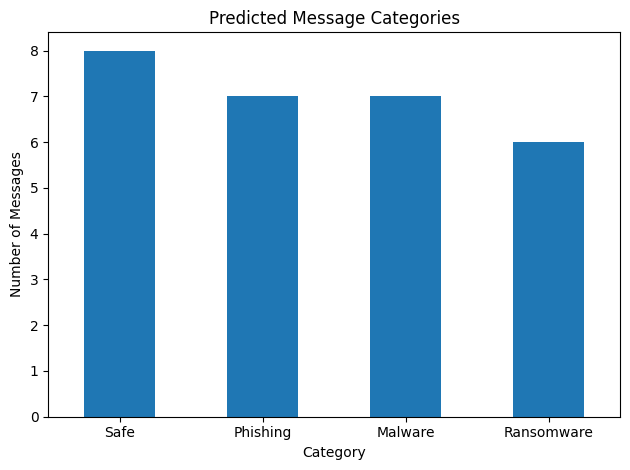

In [ ]:
order = ['Safe', 'Phishing', 'Malware', 'Ransomware']

category_counts = df['predicted_category'].value_counts().reindex(
    order,
    fill_value=0
)

category_counts.plot(kind='bar')

plt.title('Predicted Message Categories')
plt.xlabel('Category')
plt.ylabel('Number of Messages')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
new_message = input("Enter a new message: ")

category, matched, score = classify_message(new_message)

if category == 'Safe':
    risk = 'Low'
    action = 'Continue normal caution.'
elif category == 'Ransomware' or score >= 2:
    risk = 'High'
    action = 'Do not click/open; isolate if required and report.'
else:
    risk = 'Medium'
    action = 'Do not interact; verify the sender and report.'

print("\nClassification:", category)
print("Matched keywords:", matched)
print("Keyword score:", score)
print("Risk level:", risk)
print("Recommended action:", action)

Enter a new message: Urgent! Your bank account is blocked. Click here to verify your password and OTP.

Classification: Phishing
Matched keywords: click here, verify, password, urgent, otp, bank, blocked
Keyword score: 7
Risk level: High
Recommended action: Do not click/open; isolate if required and report.


In [ ]:
responsible_use = [
    'Privacy: remove personal identifiers before analysis.',
    'Bias: keyword lists may not cover every writing style.',
    'False alarms: safe messages may contain warning words.',
    'Accountability: humans remain responsible for action.',
    'Human review: high-risk or unclear cases must be checked.'
]

for point in responsible_use:
    print('-', point)

- Privacy: remove personal identifiers before analysis.
- Bias: keyword lists may not cover every writing style.
- False alarms: safe messages may contain warning words.
- Accountability: humans remain responsible for action.
- Human review: high-risk or unclear cases must be checked.


In [ ]:
df.to_csv('Lab1_Final_Result.csv', index=False)

print('Saved: Lab1_Final_Result.csv')

Saved: Lab1_Final_Result.csv
